# Cohort-Weighted Writer-Adaptive Metric Estimation

A second estimator for the writer-specific similarity metric, and a direct comparison against the
first. v9 weighted each dissimilarity component by the inverse of the writer's own spread on it,
on the reasoning that a component the writer is consistent on should count heavily. That reasoning
has a known weakness: a component can have a narrow spread because it is uninformative or
saturated rather than because it discriminates, and inverse-spread weighting cannot tell the two
apart.

**The correction.** A component earns weight when other people's signatures differ from this
writer's *and* this writer's own signatures agree with each other. The weight becomes a ratio of
between-writer spread to within-writer spread, which is the standard discriminative form of a
diagonal metric.

**The genuine-only constraint is preserved.** The between-writer term is computed from other
enrolled writers' *genuine* signatures, which an institution holding specimens for several account
holders already possesses. No forged signature of any writer enters the estimation at any stage.

**Conditions.** Four, through an identical pipeline and protocol.

| | Condition | Per-component scale |
| --- | --- | --- |
| A | v9 estimator | inverse of the writer's own spread |
| B | global metric | the population's spread |
| E | cohort-weighted estimator | within-writer spread divided by between-writer spread |
| D | trivial control | same treatment as A, on nine non-signature statistics |

A against B and E against B test whether per-writer adaptation helps at all. E against A tests
whether the discriminative form improves on the first estimator. Any condition against D tests
whether the representation reads signatures rather than acquisition artifacts.

In [ ]:
# ---- Configuration -------------------------------------------------------
import os, re, json, itertools, warnings, time
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

LOCAL_BASE = r"C:\Users\__\Downloads\bhsig\bhsig260-dataset"
COLAB_BASE = "/content/drive/MyDrive/bhsig260-dataset"
CORPORA = {"CEDAR":"cedar", "Hindi":"bhsig260-hindi", "Bengali":"bhsig260-bengali"}

SPLIT_SEED   = 20261014      # unchanged since v4a
DEV_FRACTION = 0.45
RANDOM_STATE = 0
N_ENROL      = 12
N_TEST_GEN   = 12
N_TEST_FOR   = 12
TARGET_SIZE  = (100, 100)
MAX_ASPECT   = 2.5
DENSITY_KEEP = 0.02
EPS          = 1e-9
NU           = 0.10
N_BOOT       = 2000
COHORT_WRITERS   = 4         # other writers used as surrogate impostors
COHORT_PER_WRITER = 6        # of their enrolled genuine signatures
FEATURE_CACHE = "v9_features.npz"      # reused if present; otherwise rebuilt here
RUN_CONFIRMATION = False

def resolve_base():
    for cand in (LOCAL_BASE, os.path.join(os.getcwd(), "bhsig260-dataset")):
        if os.path.isdir(cand): return cand, "local"
    if os.path.isdir(COLAB_BASE): return COLAB_BASE, "colab (already mounted)"
    try:
        from google.colab import drive; drive.mount("/content/drive")
        if os.path.isdir(COLAB_BASE): return COLAB_BASE, "colab"
    except ImportError: pass
    return None, "none (feature cache only)"

BASE, WHERE = resolve_base()
print("numpy", np.__version__, "| pandas", pd.__version__, "| data:", WHERE)
try: display
except NameError: from IPython.display import display

numpy 2.5.2 | pandas 3.0.5 | data: local


## 1. Manifest

If the v9 feature cache is present the manifest is reconstructed from the paths it stores, so the
writers and the split are identical to v9 without re-reading any image. Otherwise the corpora are
discovered and featurised exactly as in v9.

In [3]:
IMG_EXT  = {".png",".jpg",".jpeg",".tif",".tiff",".bmp"}
RE_CEDAR = re.compile(r"^(original|forgeries)[_-](\d+)[_-](\d+)", re.I)
RE_BHSIG = re.compile(r"^([BH])-S-(\d+)-([GF])-(\d+)", re.I)

def corpus_of(path):
    p = path.replace("\\","/").lower()
    if "/cedar" in p or "\\cedar" in p: return "CEDAR"
    if "hindi" in p:   return "Hindi"
    if "bengali" in p: return "Bengali"
    return None

def parse_path(path):
    stem = os.path.splitext(os.path.basename(path.replace("\\","/")))[0]
    c = corpus_of(path)
    if c is None: return None
    m = RE_CEDAR.match(stem)
    if m: return dict(corpus=c, writer=f"{c}-{int(m.group(2)):03d}",
                      label="genuine" if m.group(1).lower()=="original" else "forged",
                      index=int(m.group(3)), path=path)
    m = RE_BHSIG.match(stem)
    if m: return dict(corpus=c, writer=f"{c}-{int(m.group(2)):03d}",
                      label="genuine" if m.group(3).upper()=="G" else "forged",
                      index=int(m.group(4)), path=path)
    return None

def walk_corpora(base):
    out=[]
    for key, folder in CORPORA.items():
        root=None
        for dp,dirs,_ in os.walk(base):
            for d in dirs:
                if d.lower()==folder or d.lower().startswith(folder):
                    root=os.path.join(dp,d); break
            if root: break
        if not root: print("MISSING:", key); continue
        for dp,_,fs in os.walk(root):
            for f in fs:
                if os.path.splitext(f)[1].lower() in IMG_EXT: out.append(os.path.join(dp,f))
    return out

if os.path.exists(FEATURE_CACHE):
    _z = np.load(FEATURE_CACHE, allow_pickle=True)
    FEATURES = {k:_z[k].item() for k in _z.keys()}
    paths = list(next(iter(FEATURES.values())).keys())
    print("feature cache loaded:", len(paths), "images |", list(FEATURES))
else:
    FEATURES = None
    paths = walk_corpora(BASE)
    print("no cache; images found:", len(paths))

manifest = pd.DataFrame([r for r in (parse_path(p) for p in paths) if r])
print("parsed:", len(manifest))

no cache; images found: 16680
parsed: 16680


In [4]:
# Writer split: same seed and fraction as every notebook since v4a.
rng = np.random.RandomState(SPLIT_SEED); dev=[]
for corpus, g in manifest.groupby("corpus"):
    ws = np.array(sorted(g.writer.unique())); perm = rng.permutation(len(ws))
    dev.extend(ws[perm[:max(2, int(round(DEV_FRACTION*len(ws))))]].tolist())
dev = set(dev)
manifest["split"] = np.where(manifest.writer.isin(dev), "dev", "reserved")
display(manifest.groupby(["corpus","split"]).writer.nunique().unstack(fill_value=0))

SETS = {}
for (c,w), g in manifest.groupby(["corpus","writer"]):
    gen = g[g.label=="genuine"].sort_values("index").path.tolist()
    forg= g[g.label=="forged" ].sort_values("index").path.tolist()
    en, tg, tf = gen[:N_ENROL], gen[N_ENROL:N_ENROL+N_TEST_GEN], forg[:N_TEST_FOR]
    if len(en)==N_ENROL and tg and tf:
        SETS[(c,w,g.split.iloc[0])] = (en,tg,tf)
DEV_KEYS = [k for k in SETS if k[2]=="dev"]
RES_KEYS = [k for k in SETS if k[2]=="reserved"]
BY_CORPUS = {}
for k in DEV_KEYS: BY_CORPUS.setdefault(k[0], []).append(k)
print("usable writers:", len(SETS), "| dev:", len(DEV_KEYS), "| reserved:", len(RES_KEYS))

split,dev,reserved
corpus,,
Bengali,45,55
CEDAR,25,30
Hindi,72,88


usable writers: 314 | dev: 142 | reserved: 172


In [5]:
# Features, if the cache was absent.
if FEATURES is None:
    from PIL import Image
    from skimage.feature import hog as sk_hog
    HOG_KW = dict(orientations=9, pixels_per_cell=(10,10), cells_per_block=(2,2),
                  block_norm="L2-Hys", feature_vector=True)
    def otsu_threshold(a):
        h=np.bincount(a.ravel(),minlength=256).astype(float); t=h.sum()
        if t==0: return 127
        om=np.cumsum(h)/t; mu=np.cumsum(h*np.arange(256))/t; mt=mu[-1]
        den=om*(1-om); den[den==0]=1e-12
        return int(np.argmax((mt*om-mu)**2/den))
    def load_gray(p):
        with Image.open(p) as im:
            if im.mode not in ("L","I;16","I"): im=im.convert("L")
            a=np.asarray(im)
        if a.dtype!=np.uint8:
            a=(255.0*(a.astype(float)-a.min())/max(1e-9,(a.max()-a.min()))).astype(np.uint8)
        return a
    def preprocess(p):
        a=load_gray(p); a=(255-a).astype(np.uint8)
        t=otsu_threshold(a); a=np.where(a>t,a,0).astype(np.uint8)
        r=a.sum(1).astype(float); c=a.sum(0).astype(float)
        ri=np.where(r>=DENSITY_KEEP*(r.max() or 1))[0]; ci=np.where(c>=DENSITY_KEEP*(c.max() or 1))[0]
        b=a[ri.min():ri.max()+1, ci.min():ci.max()+1] if len(ri) and len(ci) else a
        h,w=b.shape[:2]
        if w/h>MAX_ASPECT:
            nh=int(np.ceil(w/MAX_ASPECT)); pd_=nh-h; b=np.pad(b,((pd_//2,pd_-pd_//2),(0,0)))
        elif h/w>MAX_ASPECT:
            nw=int(np.ceil(h/MAX_ASPECT)); pd_=nw-w; b=np.pad(b,((0,0),(pd_//2,pd_-pd_//2)))
        return np.asarray(Image.fromarray(b.astype(np.uint8)).resize(TARGET_SIZE, Image.BILINEAR))
    def f_stats(img):
        a=img.astype(float); t=otsu_threshold(img); h,w=img.shape[:2]
        return np.array([a.mean(),a.std(),np.median(a),np.percentile(a,5),np.percentile(a,95),
                         float((img<=t).mean()),float(h),float(w),float(w)/float(h)],dtype=np.float32)
    need=sorted({p for v in SETS.values() for l in v for p in l})
    FEATURES={"HOG":{}, "RAW":{}, "CTRL":{}}
    for i,p in enumerate(need,1):
        im=preprocess(p)
        FEATURES["HOG"][p]=sk_hog(im,**HOG_KW).astype(np.float32)
        FEATURES["RAW"][p]=(im.astype(np.float32)/255.0).ravel()
        FEATURES["CTRL"][p]=f_stats(im)
        if i%500==0: print(f"  {i}/{len(need)}")
    np.savez_compressed(FEATURE_CACHE, **{k:np.array(v,dtype=object) for k,v in FEATURES.items()})
    print("cache written:", FEATURE_CACHE)
for k in FEATURES: print(f"  {k:5s} dim {np.asarray(next(iter(FEATURES[k].values()))).size}")

  500/11304
  1000/11304
  1500/11304
  2000/11304
  2500/11304
  3000/11304
  3500/11304
  4000/11304
  4500/11304
  5000/11304
  5500/11304
  6000/11304
  6500/11304
  7000/11304
  7500/11304
  8000/11304
  8500/11304
  9000/11304
  9500/11304
  10000/11304
  10500/11304
  11000/11304
cache written: v9_features.npz
  HOG   dim 2916
  RAW   dim 10000
  CTRL  dim 9


## 2. Pair descriptor

Unchanged from v9: seventeen symmetric dissimilarity components over a pair of feature vectors.
Twelve enrolled signatures give 66 such vectors, which is 3.9 samples per dimension.

In [6]:
PAIR_COMPONENTS = ["L1","L2","Linf","cosine","correlation","canberra","braycurtis",
    "absdiff_std","absdiff_median","absdiff_p90","d_mean","d_std","d_max","d_energy",
    "chi2","hist_inter","d_sum"]
D_PAIR = len(PAIR_COMPONENTS)

def pair_descriptor(a, b):
    a=np.asarray(a,float); b=np.asarray(b,float); d=np.abs(a-b)
    na,nb=np.linalg.norm(a),np.linalg.norm(b)
    cos=1.0-float(a@b)/(na*nb+EPS)
    ac,bc=a-a.mean(),b-b.mean()
    cor=1.0-float(ac@bc)/(np.linalg.norm(ac)*np.linalg.norm(bc)+EPS)
    can=float(np.sum(d/(np.abs(a)+np.abs(b)+EPS)))
    bray=float(d.sum()/(np.abs(a+b).sum()+EPS))
    chi2=float(np.sum(d**2/(np.abs(a)+np.abs(b)+EPS)))
    hist=1.0-float(np.minimum(np.abs(a),np.abs(b)).sum())/(max(np.abs(a).sum(),np.abs(b).sum())+EPS)
    return np.array([d.mean(), np.sqrt((d**2).sum()), d.max(), cos, cor, can, bray,
        d.std(), np.median(d), np.percentile(d,90),
        abs(a.mean()-b.mean()), abs(a.std()-b.std()), abs(a.max()-b.max()),
        abs((a**2).sum()-(b**2).sum()), chi2, hist, abs(a.sum()-b.sum())], float)

def enrolled_pairs(v):
    return np.array([pair_descriptor(v[i],v[j]) for i,j in itertools.combinations(range(len(v)),2)])
def query_pairs(q,v):
    return np.array([pair_descriptor(q,x) for x in v])

_a=np.random.RandomState(0).rand(50); _b=np.random.RandomState(1).rand(50)
assert np.allclose(pair_descriptor(_a,_b), pair_descriptor(_b,_a)), "descriptor not symmetric"
print(f"{D_PAIR} components, symmetry verified | {N_ENROL*(N_ENROL-1)//2} pairs"
      f" = {N_ENROL*(N_ENROL-1)//2/D_PAIR:.2f} per dimension")

17 components, symmetry verified | 66 pairs = 3.88 per dimension


## 3. The cohort, and the two estimators

The cohort for a writer is drawn from other **development** writers of the same corpus, using
only their enrolled genuine signatures. Reserved writers never appear in any cohort, so the held-out
set stays untouched. The draw is seeded from the writer's own identifier rather than from a single
advancing generator, so a writer receives the same cohort regardless of the order in which writers
are processed and the run is reproducible.

Both estimators operate on coordinates standardised against the pooled development population
first, so that a component cannot dominate through its raw units alone.

- **A** weights component *k* by the inverse of the writer's own spread on it.
- **E** weights component *k* by the between-writer spread divided by the within-writer spread.

A component on which every writer looks alike earns little weight under E and may earn a great
deal under A, which is the difference the comparison is designed to expose.

In [7]:
import hashlib

def cohort_for(key, rep, enrolled_vecs):
    """Cross pairs between this writer's enrolled signatures and other writers' enrolled genuines."""
    pool = [k for k in BY_CORPUS[key[0]] if k != key]
    if not pool: return None
    seed = int(hashlib.md5(key[1].encode()).hexdigest()[:8], 16) % (2**31)
    r = np.random.RandomState(seed)                       # per-writer, order-independent
    pick = [pool[i] for i in r.choice(len(pool), min(COHORT_WRITERS, len(pool)), replace=False)]
    out = []
    for ok in pick:
        others = [FEATURES[rep][p] for p in SETS[ok][0][:COHORT_PER_WRITER]]
        for a in enrolled_vecs:
            for b in others:
                out.append(pair_descriptor(a, b))
    return np.array(out)

def transform_for(P, condition, global_spread, P_cohort=None):
    """Return (transform, weights, scale). Every condition centres on the writer."""
    mu = P.mean(0)
    Z  = (P - mu) / global_spread                          # population-standardised
    within = Z.std(0) + EPS
    if condition == "B":
        scale_vec = global_spread.copy()
        w = 1.0 / scale_vec
    elif condition == "E":
        Zc = (P_cohort - mu) / global_spread
        between = Zc.std(0) + EPS
        ratio = between / within
        ratio = ratio / (ratio.mean() + EPS)
        scale_vec = global_spread * within / (ratio + EPS)
        w = between / within
    else:                                                  # A, and D on control features
        scale_vec = global_spread * within
        w = 1.0 / within
    return (lambda X: (X - mu) / scale_vec), w / (w.mean() + EPS), \
           float(np.exp(np.mean(np.log(scale_vec + EPS))))

print("estimators defined | cohort:", COHORT_WRITERS, "writers x",
      COHORT_PER_WRITER, "genuine signatures, seeded per writer")

estimators defined | cohort: 4 writers x 6 genuine signatures, seeded per writer


## 4. Protocol

Identical to v9. The enrolled pairs are transformed, a one-class Support Vector Machine is fitted,
a questioned signature is paired against each enrolled signature, the verdict is the majority and
the continuous score is the mean decision value. The kernel bandwidth follows the scale of the
transformed data in each condition, and its non-degeneracy is checked rather than assumed.

In [8]:
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score

def kernel_health(X, gamma):
    n = min(len(X), 60)
    idx = np.random.RandomState(RANDOM_STATE).choice(len(X), n, replace=False)
    Z = X[idx]; d2 = ((Z[:,None,:]-Z[None,:,:])**2).sum(-1)
    return float(np.median(gamma * d2[np.triu_indices(n,1)]))

def evaluate_writer(key, rep, condition, global_spread):
    corpus, writer, split = key
    enrol, tgen, tfor = SETS[key]; F = FEATURES[rep]
    ev = [F[p] for p in enrol]
    P  = enrolled_pairs(ev)
    Pc = cohort_for(key, rep, ev) if condition == "E" else None
    tf, weights, scale = transform_for(P, condition, global_spread, Pc)

    Xtr = tf(P)
    gamma = 1.0 / (Xtr.shape[1] * (Xtr.var() + EPS))
    health = kernel_health(Xtr, gamma)
    m = OneClassSVM(kernel="rbf", nu=NU, gamma=gamma, tol=1e-10).fit(Xtr)

    sc, ac = [], []
    for p in tgen + tfor:
        s = m.decision_function(tf(query_pairs(F[p], ev)))
        sc.append(float(s.mean())); ac.append(float((s > 0).mean()))
    sc = np.array(sc); verdict = np.array(ac) > 0.5; ng = len(tgen)
    y = np.r_[np.zeros(ng), np.ones(len(tfor))]
    try: auc = float(roc_auc_score(y, -sc))
    except Exception: auc = np.nan
    return dict(corpus=corpus, writer=writer, split=split, condition=condition,
                FRR=float(1-verdict[:ng].mean()), FAR=float(verdict[ng:].mean()),
                AUC=auc, kernel_health=health, scale=scale, weights=weights)

print("protocol defined | nu =", NU)

protocol defined | nu = 0.1


In [9]:
CONDITIONS = [("A","HOG"), ("B","HOG"), ("E","HOG"), ("D","CTRL")]
LABEL = {"A":"A v9 estimator","B":"B global metric",
         "E":"E cohort-weighted","D":"D trivial control"}

GS = {}
for rep in {r for _, r in CONDITIONS}:
    Pall = np.vstack([enrolled_pairs([FEATURES[rep][p] for p in SETS[k][0]]) for k in DEV_KEYS])
    GS[rep] = Pall.std(0) + EPS
    print(f"global spread for {rep}: pooled {Pall.shape[0]} pairs")

rows=[]; t0=time.time()
for cond, rep in CONDITIONS:
    for k in DEV_KEYS: rows.append(evaluate_writer(k, rep, cond, GS[rep]))
    print(f"  {cond} done ({time.time()-t0:.0f}s)")
R = pd.DataFrame(rows); W = R.pop("weights")
R["label"] = R.condition.map(LABEL)

print("\nwriter-conditions with a degenerate kernel:", int((R.kernel_health < 1e-3).sum()), "of", len(R))
summary = R.groupby(["corpus","label"])[["FRR","FAR","AUC"]].mean().round(4)
summary["balanced_acc"] = (1 - (summary.FRR + summary.FAR)/2).round(4)
display(summary)

piv = R.pivot_table(index="corpus", columns="condition", values="AUC").round(4)
for c in ["A","B","E"]:
    if c in piv: piv[f"{c}-D"] = (piv[c]-piv["D"]).round(4)
print("\nMean per-writer AUC, and margin over the trivial control:")
display(piv)

global spread for CTRL: pooled 9372 pairs
global spread for HOG: pooled 9372 pairs
  A done (33s)
  B done (66s)
  E done (124s)
  D done (136s)

writer-conditions with a degenerate kernel: 77 of 568


FRR     FAR     AUC  balanced_acc
corpus  label                                                  
Bengali A v9 estimator     0.3074  0.2889  0.7182        0.7018
        B global metric    0.3056  0.3241  0.7009        0.6852
        D trivial control  0.1074  0.2870  0.8799        0.8028
        E cohort-weighted  0.1630  0.4537  0.6589        0.6916
CEDAR   A v9 estimator     0.3733  0.1733  0.8211        0.7267
        B global metric    0.3500  0.1967  0.8167        0.7266
        D trivial control  0.2733  0.3633  0.7489        0.6817
        E cohort-weighted  0.2800  0.2433  0.8206        0.7384
Hindi   A v9 estimator     0.3426  0.1979  0.8126        0.7298
        B global metric    0.3102  0.2280  0.8089        0.7309
        D trivial control  0.1562  0.5405  0.6886        0.6517
        E cohort-weighted  0.1991  0.3461  0.7809        0.7274


Mean per-writer AUC, and margin over the trivial control:


condition,A,B,D,E,A-D,B-D,E-D
corpus,,,,,,,
Bengali,0.7182,0.7009,0.8799,0.6589,-0.1617,-0.1790,-0.2210
CEDAR,0.8211,0.8167,0.7489,0.8206,0.0722,0.0678,0.0717
Hindi,0.8126,0.8089,0.6886,0.7809,0.1240,0.1203,0.0923


## 5. Hypothesis tests

Three comparisons per corpus, each paired across writers, tested by Wilcoxon signed-rank with Holm
correction across the family and reported with bootstrap confidence intervals over writers.

`E vs B` and `A vs B` ask whether per-writer adaptation helps at all. `E vs A` asks whether the
discriminative form improves on the inverse-spread form. `E vs D` and `A vs D` ask whether the
representation reads signatures rather than acquisition artifacts.

In [10]:
from scipy.stats import wilcoxon

def holm(p):
    p=np.asarray(p,float); order=np.argsort(p); m=len(p); adj=np.empty(m); run=0.0
    for rank,i in enumerate(order):
        run=max(run,(m-rank)*p[i]); adj[i]=min(1.0,run)
    return adj

def boot_ci(d, n=N_BOOT, seed=RANDOM_STATE):
    r=np.random.RandomState(seed); d=np.asarray(d,float); d=d[~np.isnan(d)]
    if len(d)<2: return (np.nan,np.nan)
    bs=d[r.randint(0,len(d),(n,len(d)))].mean(1)
    return float(np.percentile(bs,2.5)), float(np.percentile(bs,97.5))

LOWER_IS_BETTER={"FRR","FAR"}
PAIRS=[("A","B","per-writer (v9) vs global"),
       ("E","B","per-writer (cohort) vs global"),
       ("E","A","cohort vs v9 estimator"),
       ("A","D","v9 vs trivial control"),
       ("E","D","cohort vs trivial control")]

tests=[]
for corpus,g in R.groupby("corpus"):
    pv={c:g[g.condition==c].set_index("writer") for c in g.condition.unique()}
    for metric in ["AUC","FRR","FAR"]:
        for c1,c2,name in PAIRS:
            if c1 not in pv or c2 not in pv: continue
            idx=pv[c1].index.intersection(pv[c2].index)
            x=pv[c1].loc[idx,metric].values; y=pv[c2].loc[idx,metric].values
            ok=~(np.isnan(x)|np.isnan(y)); x,y=x[ok],y[ok]
            diff=(y-x) if metric in LOWER_IS_BETTER else (x-y)
            st,p=(np.nan,np.nan) if (len(x)<5 or np.allclose(diff,0)) else wilcoxon(x,y)
            lo,hi=boot_ci(diff)
            tests.append(dict(corpus=corpus, comparison=name, metric=metric, n=int(len(x)),
                              mean_diff=float(diff.mean()), ci_lo=lo, ci_hi=hi, p_raw=p))
T=pd.DataFrame(tests); ok=T.p_raw.notna()
T.loc[ok,"p_holm"]=holm(T.loc[ok,"p_raw"].values); T["significant"]=T.p_holm<0.05

print("AUC comparisons (positive mean_diff favours the first condition named):")
display(T[T.metric=="AUC"][["corpus","comparison","n","mean_diff","ci_lo","ci_hi","p_holm","significant"]].round(4))
print("\nAll metrics:")
display(T[["corpus","comparison","metric","mean_diff","p_holm","significant"]].round(4))

AUC comparisons (positive mean_diff favours the first condition named):


,corpus,comparison,n,mean_diff,ci_lo,ci_hi,p_holm,significant
0,Bengali,per-writer (v9) vs global,45,0.0173,0.0036,0.0316,0.6842,False
1,Bengali,per-writer (cohort) vs global,45,-0.0421,-0.0789,-0.0083,0.8410,False
2,Bengali,cohort vs v9 estimator,45,-0.0593,-0.0917,-0.0275,0.0255,True
3,Bengali,v9 vs trivial control,45,-0.1617,-0.2332,-0.0936,0.0051,True
4,Bengali,cohort vs trivial control,45,-0.2211,-0.3019,-0.1445,0.0004,True
15,CEDAR,per-writer (v9) vs global,25,0.0044,-0.0099,0.0204,1.0000,False
16,CEDAR,per-writer (cohort) vs global,25,0.0039,-0.0222,0.0342,1.0000,False
17,CEDAR,cohort vs v9 estimator,25,-0.0006,-0.0178,0.0186,1.0000,False
18,CEDAR,v9 vs trivial control,25,0.0722,-0.0350,0.1721,1.0000,False
19,CEDAR,cohort vs trivial control,25,0.0717,-0.0315,0.1691,1.0000,False



All metrics:


,corpus,comparison,metric,mean_diff,p_holm,significant
0,Bengali,per-writer (v9) vs global,AUC,0.0173,0.6842,False
1,Bengali,per-writer (cohort) vs global,AUC,-0.0421,0.8410,False
2,Bengali,cohort vs v9 estimator,AUC,-0.0593,0.0255,True
3,Bengali,v9 vs trivial control,AUC,-0.1617,0.0051,True
4,Bengali,cohort vs trivial control,AUC,-0.2211,0.0004,True
5,Bengali,per-writer (v9) vs global,FRR,-0.0019,1.0000,False
6,Bengali,per-writer (cohort) vs global,FRR,0.1426,0.0007,True
7,Bengali,cohort vs v9 estimator,FRR,0.1444,0.0007,True
8,Bengali,v9 vs trivial control,FRR,-0.2000,0.0010,True
9,Bengali,cohort vs trivial control,FRR,-0.0556,0.4732,False


## 6. The estimated metrics

The weights are reported relative to the population, so a value above one means the writer is more
consistent than average on that component and below one means less. Their spread across writers is
what the per-writer claim depends on: if every writer receives the same profile, the estimator is
not adapting to anyone and no advantage over a global metric should be expected.

A v9 estimator: profile sd across writers  mean 1.1512  max 7.5556
   weight range 0.36 to 8.94 (25x) | heaviest: absdiff_median 8.94, d_max 1.73, d_std 0.51
E cohort-weighted: profile sd across writers  mean 1.1032  max 7.2775
   weight range 0.19 to 9.38 (50x) | heaviest: absdiff_median 9.38, d_max 1.76, d_std 0.79


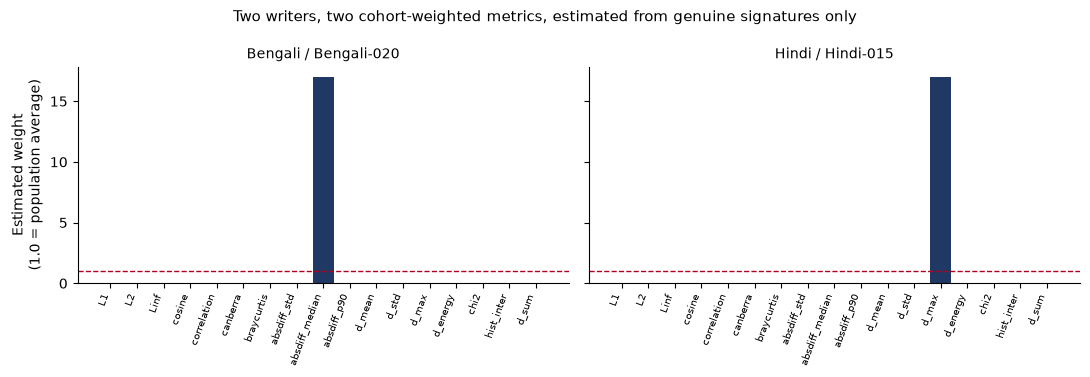

most dissimilar pair shown; mean absolute profile difference 2.0000


In [11]:
import matplotlib.pyplot as plt

def profile_frame(cond):
    idx = R.index[R.condition == cond]
    return pd.DataFrame([W.loc[i] for i in idx],
                        index=pd.MultiIndex.from_frame(R.loc[idx, ["corpus","writer"]]),
                        columns=PAIR_COMPONENTS)

for cond in ["A","E"]:
    Wc = profile_frame(cond); sd = Wc.std(axis=0)
    print(f"{LABEL[cond]}: profile sd across writers  mean {sd.mean():.4f}  max {sd.max():.4f}")
    m = Wc.mean(axis=0)
    print(f"   weight range {m.min():.2f} to {m.max():.2f}"
          f" ({m.max()/max(m.min(),1e-9):.0f}x) | heaviest: "
          + ", ".join(f"{k} {v:.2f}" for k,v in m.sort_values(ascending=False).head(3).items()))

WE = profile_frame("E"); sd = WE.std(axis=0)
if sd.max() < 0.02:
    print("\nProfiles near-identical across writers; the estimator is not adapting. Reported, not hidden.")
else:
    from itertools import combinations
    idx=list(WE.index); best,bd=None,-1
    for i,j in combinations(range(len(idx)),2):
        d=float(np.abs(WE.iloc[i].values-WE.iloc[j].values).mean())
        if d>bd: bd,best=d,(idx[i],idx[j])
    fig,axes=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
    for ax,key in zip(axes,best):
        v=WE.loc[key]
        ax.bar(range(len(v)), v.values, color="#1F3864")
        ax.axhline(1.0,color="#B00020",lw=1.0,ls="--")
        ax.set_xticks(range(len(v))); ax.set_xticklabels(PAIR_COMPONENTS,rotation=70,fontsize=7,ha="right")
        ax.set_title(f"{key[0]} / {key[1]}",fontsize=10)
        ax.spines[["top","right"]].set_visible(False)
    axes[0].set_ylabel("Estimated weight\n(1.0 = population average)")
    fig.suptitle("Two writers, two cohort-weighted metrics, estimated from genuine signatures only",fontsize=11)
    plt.tight_layout(); plt.show()
    print(f"most dissimilar pair shown; mean absolute profile difference {bd:.4f}")

In [12]:
R.drop(columns=["label"]).to_csv("v10_per_writer_results.csv", index=False)
T.to_csv("v10_hypothesis_tests.csv", index=False)
profile_frame("E").to_csv("v10_estimated_metrics.csv")
print("written: v10_per_writer_results.csv, v10_hypothesis_tests.csv, v10_estimated_metrics.csv")

written: v10_per_writer_results.csv, v10_hypothesis_tests.csv, v10_estimated_metrics.csv


## 7. Confirmation run

The reserved writers have not been read by any notebook in this project and do not appear in any
cohort. They are evaluated once, after every design decision is final. Setting the flag in the
configuration cell to True consumes that opportunity and it cannot be undone.

In [13]:
if RUN_CONFIRMATION:
    conf=[]
    for cond,rep in CONDITIONS:
        for k in RES_KEYS: conf.append(evaluate_writer(k, rep, cond, GS[rep]))
    RC=pd.DataFrame(conf); RC.pop("weights")
    display(RC.groupby(["corpus","condition"])[["FRR","FAR","AUC"]].mean().round(4))
    RC.to_csv("v10_confirmation_results.csv", index=False)
    print("confirmation written. This run is final.")
else:
    print("RUN_CONFIRMATION is False. Reserved writers untouched:", len(RES_KEYS))

RUN_CONFIRMATION is False. Reserved writers untouched: 172


## 8. Reading the result

Two estimators built on opposing assumptions are compared against the same global metric and the
same control. If neither beats the global metric, the finding is that per-writer weighting of this
representation carries no measurable advantage, and the agreement of two independent formulations
makes that a stronger statement than a single failure would be.

If a condition fails to beat the trivial control on a corpus, that corpus's reported accuracy
cannot be attributed to reading signatures, and the v8 audit of that corpus is the explanation to
consult rather than the model.